# Domain: Insurance

## Context of Dataset

This dataset is used to build a **regression** model that predicts a customer's annual medical
**insurance charges** based on personal and health attributes.

Attribute information:
- `age` — age of the primary beneficiary (years)
- `sex` — insurance contractor's gender (`male` / `female`)
- `bmi` — body mass index
- `children` — number of dependents covered by the insurance plan
- `smoker` — whether the person smokes (`yes` / `no`)
- `region` — the beneficiary's residential area in the US (`northeast`, `northwest`, `southeast`, `southwest`)

Target:
- `charges` — individual medical costs billed by health insurance (continuous, in USD)

## Task 1: Data Analysis Report
## Step 1: Loading the Dataset

In [4]:
# Importing required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pickle
import random

In [5]:
# Relative path (not a hardcoded, machine-specific one) — keep the CSV alongside this notebook

data_path = '/Users/anmolgupta/Desktop/Datamites Internship/Insurance_cost_prediction (PRCP-1021)/datasets_13720_18513_insurance(1).csv'

In [6]:
original_data = pd.read_csv(data_path)
print(original_data.shape)
original_data.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
df = original_data.copy()  # working copy so the original loaded data stays untouched
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Step 2: Initial Basic Checks

In [9]:
df.shape

(1338, 7)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [11]:
df.isnull().sum()   # check for missing values

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [12]:
df.duplicated().sum()   # check for duplicate rows

1

In [13]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [14]:
df.describe(include='object')   # summary of categorical columns

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


#### Note:

There are **no missing values**, but there is **1 duplicate row**, which is removed in the preprocessing
step below. `sex`, `smoker`, and `region` are categorical and need encoding before modelling. The target,
`charges`, is continuous — this is a **regression** problem, unlike the classification problems tackled
in the liver and heart disease notebooks, so the modelling and evaluation approach differs accordingly
(regressors instead of classifiers; R² / error-based metrics instead of accuracy / F1).

## Step 3: EDA — Univariate & Bivariate Analysis

### 1. Univariate Analysis

In [18]:
num_col = df.select_dtypes(include=['number']).columns
num_col

Index(['age', 'bmi', 'children', 'charges'], dtype='object')

#### Plotting Histograms

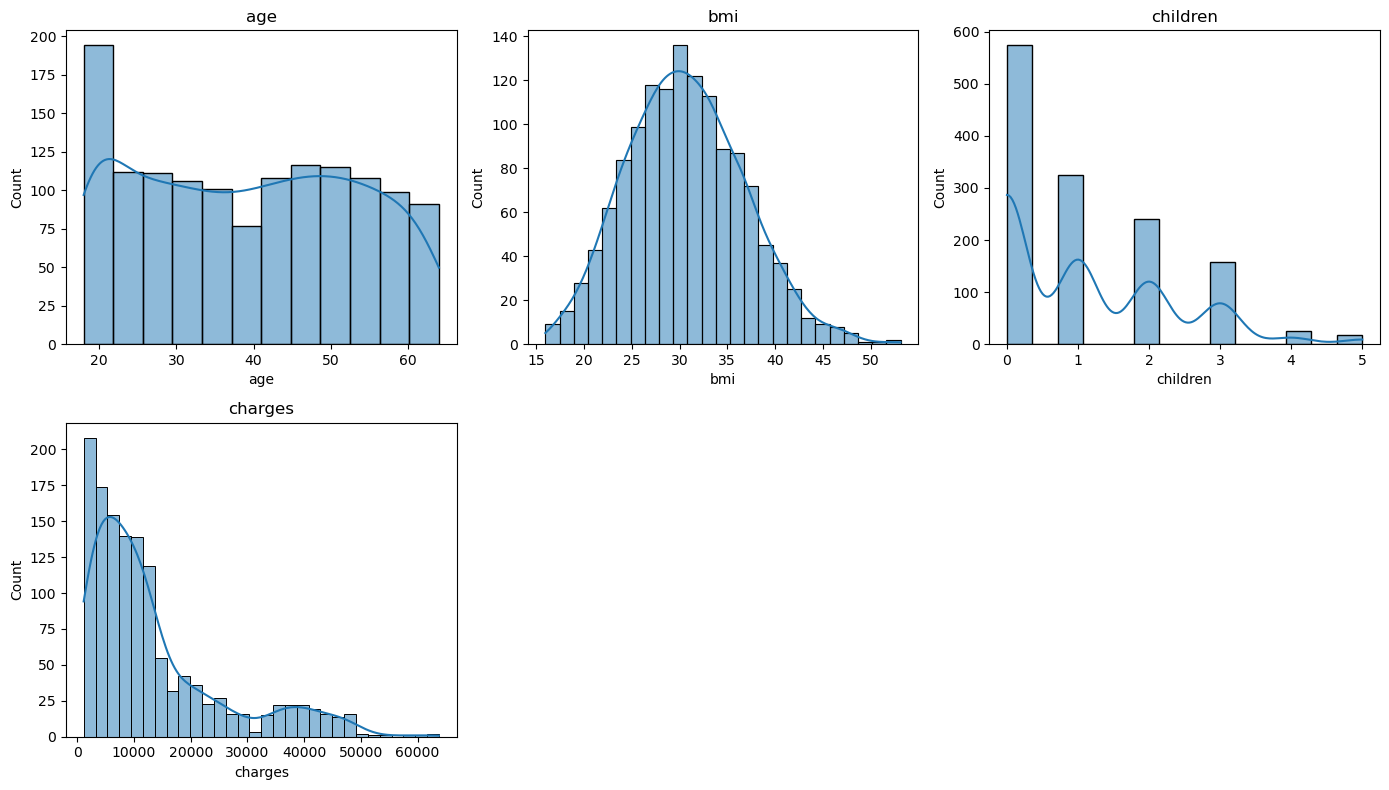

In [20]:
plt.figure(figsize=(14,8), facecolor='white')
for i, col in enumerate(num_col):
    plt.subplot(2, 3, i+1)
    sns.histplot(x=df[col], kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

#### Findings from Histograms:

- `age` is fairly evenly spread across the adult range.
- `bmi` is close to a normal distribution with a slight right-skew.
- `children` is a small-integer count (0–5), heavily weighted toward 0–2.
- `charges` (the target) is **strongly right-skewed** — most customers have modest charges, but a
  minority (largely smokers, confirmed in the bivariate analysis below) have very high charges. This
  skew matters a lot for a regression problem: it's the reason a log-transform of the target is used in
  the Feature Engineering step below, rather than being ignored as it might be for a predictor column.

#### Categorical Column Distributions

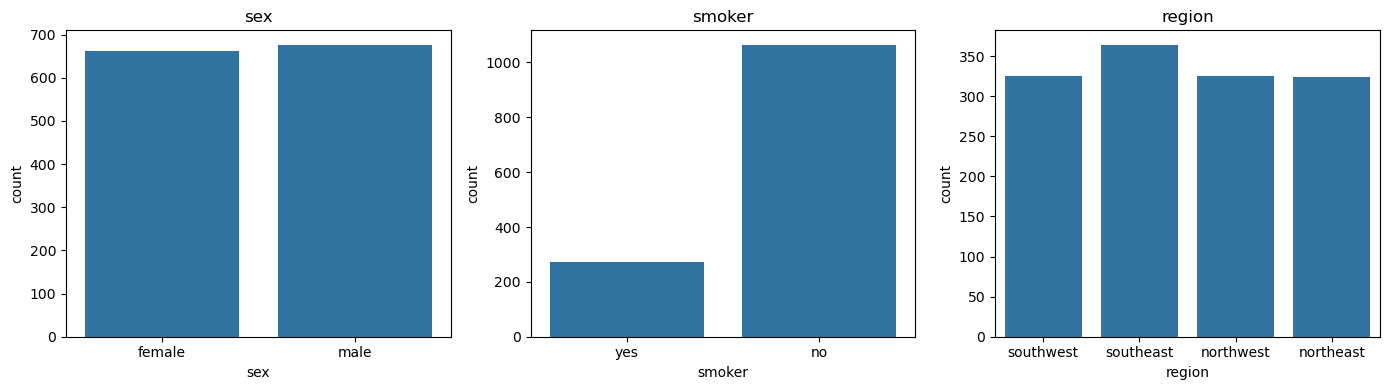

In [23]:
cat_col = ['sex', 'smoker', 'region']

plt.figure(figsize=(14,4), facecolor='white')
for i, col in enumerate(cat_col):
    plt.subplot(1, 3, i+1)
    sns.countplot(x=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

### 2. Bivariate / Multivariate Analysis

#### Plotting Boxplots (outlier check on continuous predictors)

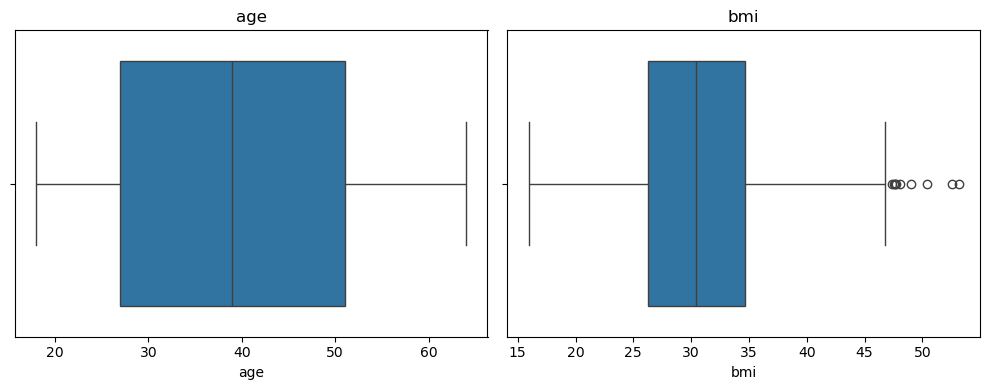

In [26]:
continuous_cols = ['age', 'bmi']

plt.figure(figsize=(10,4), facecolor='white')
for i, col in enumerate(continuous_cols):
    plt.subplot(1, 2, i+1)
    sns.boxplot(x=df[col], orient='h')
    plt.title(col)
plt.tight_layout()
plt.show()

#### Findings from Boxplots:

- `age` shows no outliers.
- `bmi` has a small number of high-end outliers, mild enough to cap rather than drop.
- `charges` (the target) is **deliberately not boxplotted for capping here** — see the note in
  Preprocessing below on why target outliers are treated differently from predictor outliers.

#### Charges vs. Key Predictors

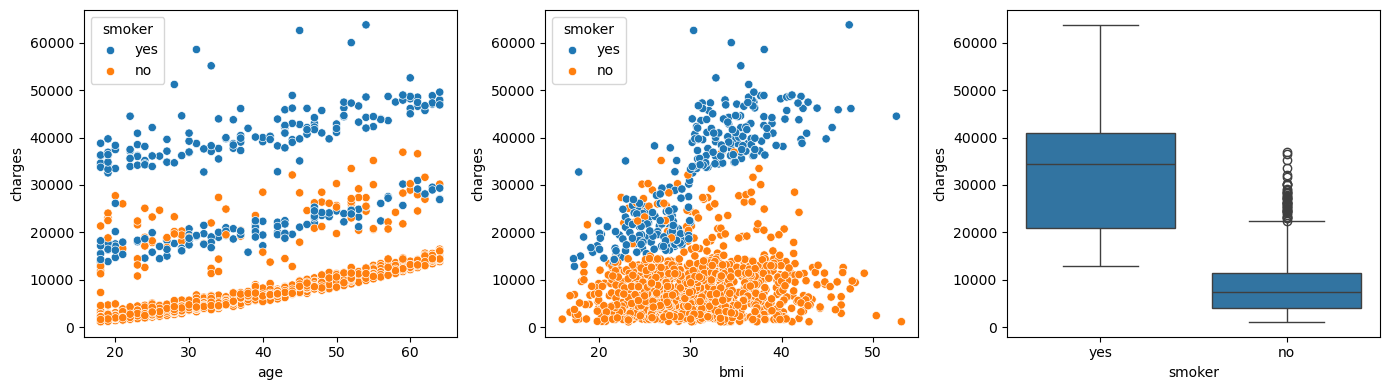

In [29]:
plt.figure(figsize=(14,4))
plt.subplot(1,3,1)
sns.scatterplot(x='age', y='charges', hue='smoker', data=df)
plt.subplot(1,3,2)
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df)
plt.subplot(1,3,3)
sns.boxplot(x='smoker', y='charges', data=df)
plt.tight_layout()
plt.show()

**Finding:** `smoker` status is by far the strongest driver of `charges` — smokers' charges run
roughly **4x** non-smokers' on average, and within smokers, `charges` climbs steeply with `bmi`. This
"smoker x bmi" interaction is clear enough here that it is engineered as an explicit feature below,
rather than left for a model to discover on its own.

In [31]:
df.groupby('smoker')['charges'].mean()

smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64

#### Correlation Heatmap

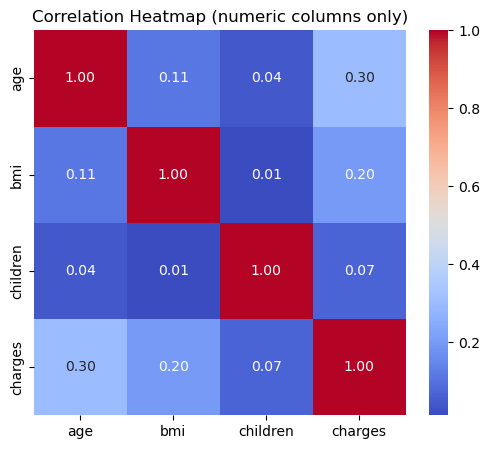

In [33]:
plt.figure(figsize=(6,5))
sns.heatmap(df.select_dtypes(include=['int64','float64']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap (numeric columns only)')
plt.show()

**Finding:** `age` and `bmi` each have only a weak linear correlation with `charges` on their own
(~0.30 and ~0.20). This is expected — `smoker` is categorical so it doesn't show up in a numeric-only
correlation matrix, but the boxplot above already showed it is the dominant factor. This is exactly why
one-hot/binary encoding `smoker` and engineering the `smoker x bmi` interaction matter more here than
adding polynomial terms on `age`/`bmi` alone would.

## Step 4: Data Preprocessing

#### Imputing Null Values

There are no null values in this dataset (confirmed above). The code below is kept as a defensive,
reusable safeguard for future data refreshes: median imputation for the continuous columns, mode for
the categorical ones.

In [37]:
continuous_cols_all = ['age', 'bmi']
categorical_cols_all = ['sex', 'children', 'smoker', 'region']

for c in continuous_cols_all:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median())

for c in categorical_cols_all:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].mode()[0])

df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

#### Dropping Duplicate Rows

In [39]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after de-duplication:', df.shape)

Duplicate rows: 1
Shape after de-duplication: (1337, 7)


#### Capping Outliers — Predictors Only, Not the Target

`bmi`'s few high-end outliers are capped with the IQR method, same as the predictor-outlier handling in
the heart disease notebook.

**Important difference from the classification notebooks:** `charges` (the target) is **not** capped or
winsorized here, even though it has a long right tail. In a regression problem the target's spread *is*
the signal the model is being trained to predict — capping it would throw away genuine information about
high-cost patients (largely smokers) rather than removing noisy/erroneous data. Instead, the target's
skew is handled with a **log-transform** in the Feature Engineering step, which is the standard,
information-preserving way to deal with a skewed regression target.

In [41]:
winsor_cols = ['bmi']

for col in winsor_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

df[winsor_cols].describe()

,bmi
count,1337.000000
mean,30.650247
std,6.059655
min,15.960000
25%,26.290000
50%,30.400000
75%,34.700000
max,47.315000


In [42]:
# Saving the cleaned dataset (mirrors the checkpoint pattern used in the earlier notebooks)

with open('Insurance_processed_file.pkl', 'wb') as f:
    pickle.dump(df, f)

## Step 5: Feature Engineering

#### Engineered Feature: `smoker_bmi`

The bivariate analysis showed charges rising steeply with `bmi`, but **only among smokers**. A plain
linear model can't discover that interaction on its own from `smoker` and `bmi` as separate columns, so
it's engineered explicitly: `smoker_bmi = bmi` for smokers, `0` for non-smokers. Tree-based models
(Random Forest, Gradient Boosting, XGBoost) can often find this interaction unaided, but the linear
models benefit from having it spelled out — and it costs nothing to include for every model.

In [45]:
df['smoker_flag'] = (df['smoker'] == 'yes').astype(int)
df['smoker_bmi'] = df['bmi'] * df['smoker_flag']

df[['bmi', 'smoker', 'smoker_flag', 'smoker_bmi']].head()

,bmi,smoker,smoker_flag,smoker_bmi
0,27.900,yes,1,27.9
1,33.770,no,0,0.0
2,33.000,no,0,0.0
3,22.705,no,0,0.0
4,28.880,no,0,0.0


#### Log-Transforming the Target

`charges` is right-skewed (confirmed in the EDA step). Models are trained to predict `log1p(charges)`
instead of raw `charges`; predictions are converted back with `expm1(...)` before every evaluation
metric is computed, so all reported R² / MAE / MSE / RMSE values below are on the **original charges
scale**, not the log scale — they stay directly comparable and interpretable in dollars.

In [47]:
df['log_charges'] = np.log1p(df['charges'])
df[['charges', 'log_charges']].head()

,charges,log_charges
0,16884.92400,9.734236
1,1725.55230,7.453882
2,4449.46200,8.400763
3,21984.47061,9.998137
4,3866.85520,8.260455


#### Defining Column Groups for the Preprocessing Pipeline

In [49]:
cat_cols = ['sex', 'smoker', 'region']            # nominal categorical -> One-Hot Encode
scale_cols = ['age', 'bmi', 'children', 'smoker_bmi']  # continuous / engineered -> Standard Scale

#### Building the Preprocessing Pipeline

In [51]:
preprocessor = ColumnTransformer([
    ('OHE', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_cols),
    ('SS', StandardScaler(), scale_cols),
])

preprocessor

ColumnTransformer(transformers=[('OHE',
                                 OneHotEncoder(drop='if_binary',
                                               handle_unknown='ignore'),
                                 ['sex', 'smoker', 'region']),
                                ('SS', StandardScaler(),
                                 ['age', 'bmi', 'children', 'smoker_bmi'])])

In [52]:
# Saving the preprocessor for re-use / deployment

with open('Insurance_CT.pkl', 'wb') as f:
    pickle.dump(preprocessor, f)

#### Splitting the Data into X and y

In [54]:
X = df.drop(columns=['charges', 'log_charges', 'smoker_flag'])
y = df['log_charges']              # train on the log-transformed target
y_original = df['charges']         # kept aligned by index, used only for final $-scale reporting

In [55]:
X_train_raw, X_test_raw, y_train, y_test, y_train_orig, y_test_orig = train_test_split(
    X, y, y_original, test_size=0.2, random_state=42
)

print(X_train_raw.shape, X_test_raw.shape, y_train.shape, y_test.shape)

(1069, 7) (268, 7) (1069,) (268,)


In [56]:
x_train = preprocessor.fit_transform(X_train_raw)   # fit ONLY on train — avoids leaking test info
x_test = preprocessor.transform(X_test_raw)

print(x_train.shape, x_test.shape)

(1069, 10) (268, 10)


**Note:** unlike the two classification notebooks, there is no SMOTE step here — SMOTE is a technique
for balancing classification classes, and doesn't apply to a continuous regression target.

## Task 2: Model Creation

As requested, models are compared primarily on **R² and RMSE (root mean squared error — the
"squared" error metric on the original dollar scale)**. Adjusted R², MAE, and MSE are logged alongside
for a fuller picture, since R² alone can be misleading when comparing models with different numbers of
effective features.

In [60]:
results = pd.DataFrame(index=['R2_Score', 'Adjusted_R2', 'MAE', 'MSE', 'RMSE'])
fitted_models = {}   # keep every fitted model so the best one can be recovered later, by name

n_test = x_test.shape[0]
n_features = x_test.shape[1]

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def evaluate_model(name, model, x_te=x_test, y_te_log=y_test, y_te_orig=y_test_orig, store=True):
    """Predicts on the log scale, converts back to $, and scores on the ORIGINAL charges scale."""
    y_pred_log = model.predict(x_te)
    y_pred = np.expm1(y_pred_log)   # back to original $ scale

    r2 = r2_score(y_te_orig, y_pred)
    adj_r2 = adjusted_r2(r2, n_test, n_features)
    mae = mean_absolute_error(y_te_orig, y_pred)
    mse = mean_squared_error(y_te_orig, y_pred)
    rmse = np.sqrt(mse)

    print(f'--- {name} ---')
    print('R2 Score:    ', r2)
    print('Adjusted R2: ', adj_r2)
    print('MAE:         ', mae)
    print('MSE:         ', mse)
    print('RMSE:        ', rmse)

    if store:
        results[name] = [r2, adj_r2, mae, mse, rmse]
        fitted_models[name] = model
    return r2, adj_r2, mae, mse, rmse

### Model 1: Linear Regression

In [62]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(x_train, y_train)

evaluate_model('Linear_Reg', lin_reg)

--- Linear_Reg ---
R2 Score:     0.5833520233980238
Adjusted R2:  0.5671400398726552
MAE:          4206.213405174725
MSE:          76561592.2710672
RMSE:         8749.948129621524


(0.5833520233980238,
 0.5671400398726552,
 4206.213405174725,
 76561592.2710672,
 8749.948129621524)

### Model 2: Support Vector Regressor

In [64]:
from sklearn.svm import SVR

svr = SVR()
svr.fit(x_train, y_train)

evaluate_model('SVR', svr)

--- SVR ---
R2 Score:     0.8688645696229972
Adjusted R2:  0.863762023693931
MAE:          2273.2375714813447
MSE:          24096930.54241366
RMSE:         4908.862448919674


(0.8688645696229972,
 0.863762023693931,
 2273.2375714813447,
 24096930.54241366,
 4908.862448919674)

In [65]:
# Cross-validation to check how stable the SVR is across different folds

scores = cross_val_score(SVR(), x_train, y_train, cv=5, scoring='r2', n_jobs=-1)
print(scores)
print('cross_validation_score:', scores.mean())
print('standard_deviation:', scores.std())
# std < 0.05 is generally considered a stable model

[0.75738308 0.86554363 0.79293075 0.82851413 0.8442849 ]
cross_validation_score: 0.8177312954190903
standard_deviation: 0.03837800677466415


#### Hyperparameter Tuning for SVR

In [67]:
param_grid = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.1, 0.5, 1], 'kernel': ['rbf', 'linear']}
grid = GridSearchCV(SVR(), param_grid, scoring='r2', cv=5, n_jobs=-1)
grid.fit(x_train, y_train)

grid.best_params_

{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}

In [68]:
svr_tuned = SVR(**grid.best_params_)
svr_tuned.fit(x_train, y_train)

evaluate_model('SVR_HPT', svr_tuned)

--- SVR_HPT ---
R2 Score:     0.8702081641554079
Adjusted R2:  0.865157898169237
MAE:          2352.181431587935
MSE:          23850036.899470713
RMSE:         4883.64995668923


(0.8702081641554079,
 0.865157898169237,
 2352.181431587935,
 23850036.899470713,
 4883.64995668923)

### Model 3: Decision Tree Regressor

In [70]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=42)
dt.fit(x_train, y_train)

evaluate_model('Decision_Tree', dt)

--- Decision_Tree ---
R2 Score:     0.788980404749424
Adjusted R2:  0.7807695255567946
MAE:          2939.3080315634325
MSE:          38776130.25879171
RMSE:         6227.048278180579


(0.788980404749424,
 0.7807695255567946,
 2939.3080315634325,
 38776130.25879171,
 6227.048278180579)

#### Hyperparameter Tuning for Decision Tree

In [72]:
params = {
    'criterion': ('squared_error', 'friedman_mse', 'absolute_error'),
    'max_depth': list(range(2, 14, 2)),
    'min_samples_split': [2, 5, 7, 10],
    'min_samples_leaf': list(range(1, 10)),
}

tree_cv = GridSearchCV(DecisionTreeRegressor(random_state=42), params, scoring='r2', n_jobs=-1, cv=5)
tree_cv.fit(x_train, y_train)

tree_cv.best_params_

{'criterion': 'squared_error',
 'max_depth': 4,
 'min_samples_leaf': 7,
 'min_samples_split': 2}

In [73]:
dt_tuned = DecisionTreeRegressor(**tree_cv.best_params_, random_state=42)
dt_tuned.fit(x_train, y_train)

evaluate_model('DT_HPT', dt_tuned)

--- DT_HPT ---
R2 Score:     0.8956862439867709
Adjusted R2:  0.891627342974583
MAE:          2287.9332391619732
MSE:          19168285.23033454
RMSE:         4378.160027949474


(0.8956862439867709,
 0.891627342974583,
 2287.9332391619732,
 19168285.23033454,
 4378.160027949474)

### Model 4: Random Forest Regressor

In [75]:
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(random_state=42)
rf_reg.fit(x_train, y_train)

evaluate_model('RandomForest', rf_reg)

--- RandomForest ---
R2 Score:     0.8953666872045297
Adjusted R2:  0.8912953520763013
MAE:          2058.9612353673165
MSE:          19227005.726876818
RMSE:         4384.860970073831


(0.8953666872045297,
 0.8912953520763013,
 2058.9612353673165,
 19227005.726876818,
 4384.860970073831)

#### Hyperparameter Tuning for Random Forest

In [77]:
n_estimators = [int(x) for x in np.linspace(start=100, stop=600, num=5)]
max_features = ['sqrt', 'log2', 1.0]
max_depth = [int(x) for x in np.linspace(5, 50, num=5)]
min_samples_split = [2, 5, 7, 10]
min_samples_leaf = [1, 2, 4]

random_grid = {'n_estimators': n_estimators, 'max_features': max_features,
               'max_depth': max_depth, 'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf}

rf_cv = RandomizedSearchCV(RandomForestRegressor(random_state=42), scoring='r2',
                            param_distributions=random_grid, cv=5, n_iter=30,
                            random_state=42, n_jobs=-1)
rf_cv.fit(x_train, y_train)

rf_cv.best_params_

{'n_estimators': 100,
 'min_samples_split': 7,
 'min_samples_leaf': 4,
 'max_features': 'sqrt',
 'max_depth': 38}

In [78]:
rf_tuned = RandomForestRegressor(**rf_cv.best_params_, random_state=42)
rf_tuned.fit(x_train, y_train)

evaluate_model('RF_HPT', rf_tuned)

--- RF_HPT ---
R2 Score:     0.8894151772458784
Adjusted R2:  0.8851122658546674
MAE:          2109.0845852471866
MSE:          20320631.771979995
RMSE:         4507.841143161546


(0.8894151772458784,
 0.8851122658546674,
 2109.0845852471866,
 20320631.771979995,
 4507.841143161546)

### Model 5: Gradient Boosting Regressor

In [80]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(random_state=42)
gbr.fit(x_train, y_train)

evaluate_model('Grad_Boost', gbr)

--- Grad_Boost ---
R2 Score:     0.8974958193414824
Adjusted R2:  0.8935073298216957
MAE:          2133.6712396376315
MSE:          18835764.78556698
RMSE:         4340.018984470803


(0.8974958193414824,
 0.8935073298216957,
 2133.6712396376315,
 18835764.78556698,
 4340.018984470803)

#### Hyperparameter Tuning for Gradient Boosting

In [82]:
param_grid = {
    'learning_rate': [0.01, 0.03, 0.06, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5, 6],
    'n_estimators': [50, 100, 150, 200],
}

gb_cv = RandomizedSearchCV(GradientBoostingRegressor(random_state=42), scoring='r2',
                            param_distributions=param_grid, cv=5, n_iter=20,
                            random_state=42, n_jobs=-1)
gb_cv.fit(x_train, y_train)

gb_cv.best_params_

{'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.06}

In [83]:
gb_tuned = GradientBoostingRegressor(**gb_cv.best_params_, random_state=42)
gb_tuned.fit(x_train, y_train)

evaluate_model('GB_HPT', gb_tuned)

--- GB_HPT ---
R2 Score:     0.900903564721588
Adjusted R2:  0.8970476722983034
MAE:          2001.884383333833
MSE:          18209570.907264553
RMSE:         4267.267381740281


(0.900903564721588,
 0.8970476722983034,
 2001.884383333833,
 18209570.907264553,
 4267.267381740281)

### Model 6: XGBoost Regressor

In [85]:
from xgboost import XGBRegressor   # NOTE: requires the `xgboost` package installed in this environment

xgb_reg = XGBRegressor(random_state=42)
xgb_reg.fit(x_train, y_train)

evaluate_model('XGBoost', xgb_reg)

--- XGBoost ---
R2 Score:     0.8330954415748055
Adjusted R2:  0.8266011007800509
MAE:          2741.855917458663
MSE:          30669724.72673146
RMSE:         5538.025345439605


(0.8330954415748055,
 0.8266011007800509,
 2741.855917458663,
 30669724.72673146,
 5538.025345439605)

#### Hyperparameter Tuning for XGBoost

In [87]:
param_grid = {
    'gamma': [0, 0.1, 0.2, 0.4],
    'learning_rate': [0.01, 0.03, 0.06, 0.1],
    'max_depth': [3, 4, 5, 6, 7],
    'n_estimators': [50, 100, 150],
    'reg_alpha': [0, 0.1, 0.2, 0.4],
    'reg_lambda': [0, 0.1, 0.2],
}

xgb_cv = RandomizedSearchCV(XGBRegressor(random_state=42), scoring='r2',
                             param_distributions=param_grid, cv=5, n_iter=40,
                             random_state=42, n_jobs=-1)
xgb_cv.fit(x_train, y_train)

xgb_cv.best_params_

{'reg_lambda': 0.1,
 'reg_alpha': 0.4,
 'n_estimators': 100,
 'max_depth': 3,
 'learning_rate': 0.1,
 'gamma': 0.2}

In [88]:
xgb_tuned = XGBRegressor(**xgb_cv.best_params_, random_state=42)
xgb_tuned.fit(x_train, y_train)

evaluate_model('XGB_HPT', xgb_tuned)

--- XGB_HPT ---
R2 Score:     0.8934376094106549
Adjusted R2:  0.8892912128896686
MAE:          2092.708731996764
MSE:          19581485.46950835
RMSE:         4425.097227124886


(0.8934376094106549,
 0.8892912128896686,
 2092.708731996764,
 19581485.46950835,
 4425.097227124886)

## Step 9: Analyzing the Report — Results Table

In [90]:
results_table = results.T.sort_values('R2_Score', ascending=False)
results_table.style.background_gradient(cmap='Greens', axis=0)

,R2_Score,Adjusted_R2,MAE,MSE,RMSE
GB_HPT,0.900904,0.897048,2001.884383,18209570.907265,4267.267382
Grad_Boost,0.897496,0.893507,2133.671240,18835764.785567,4340.018984
DT_HPT,0.895686,0.891627,2287.933239,19168285.230335,4378.160028
RandomForest,0.895367,0.891295,2058.961235,19227005.726877,4384.860970
XGB_HPT,0.893438,0.889291,2092.708732,19581485.469508,4425.097227
RF_HPT,0.889415,0.885112,2109.084585,20320631.771980,4507.841143
SVR_HPT,0.870208,0.865158,2352.181432,23850036.899471,4883.649957
SVR,0.868865,0.863762,2273.237571,24096930.542414,4908.862449
XGBoost,0.833095,0.826601,2741.855917,30669724.726731,5538.025345
Decision_Tree,0.788980,0.780770,2939.308032,38776130.258792,6227.048278


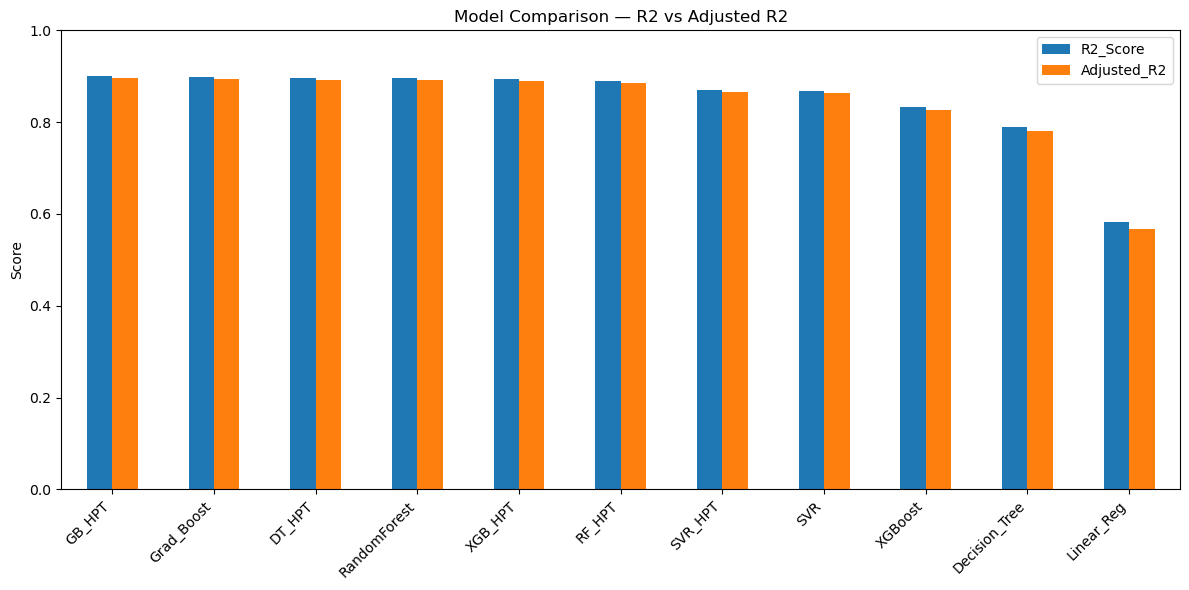

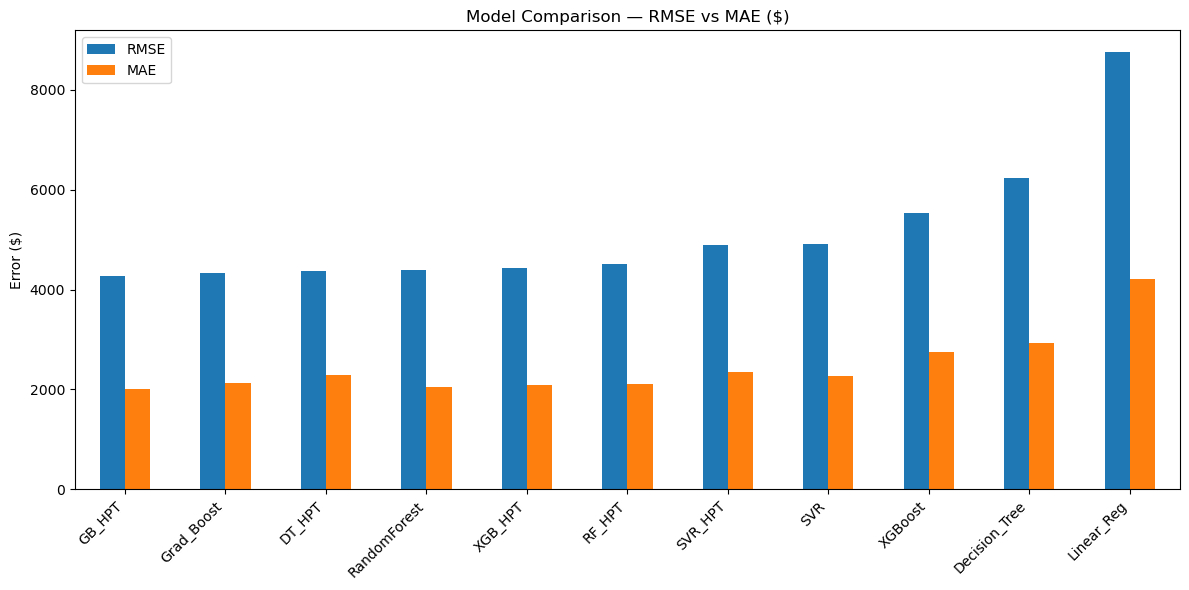

In [91]:
# Visual comparison across models

results_table[['R2_Score', 'Adjusted_R2']].plot(kind='bar', figsize=(12,6), ylim=(0,1))
plt.title('Model Comparison — R2 vs Adjusted R2')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

results_table[['RMSE', 'MAE']].plot(kind='bar', figsize=(12,6))
plt.title('Model Comparison — RMSE vs MAE ($)')
plt.ylabel('Error ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The best model is picked **programmatically** from the actual `results` table (highest R²) rather
than hand-typed, so it always reflects whatever the notebook produced on the last run.

In [93]:
best_model_name = results_table['R2_Score'].idxmax()
best_model = fitted_models[best_model_name]

print('Best model (by R2 Score):', best_model_name)
results_table.loc[[best_model_name]]

Best model (by R2 Score): GB_HPT


,R2_Score,Adjusted_R2,MAE,MSE,RMSE
GB_HPT,0.900904,0.897048,2001.884383,1.820957e+07,4267.267382


## Demo Prediction with the Best Model

(*As requested — this comes before the model comparison report.*)

A **random point from the held-out test set** (never seen during training or tuning) is run through
the best model identified above, as an end-to-end sanity check before writing up the comparison report.

In [96]:
random.seed()   # non-fixed seed so a different customer is picked each run; swap for random.seed(42) for a repeatable demo

demo_idx = random.choice(X_test_raw.index)
demo_customer_raw = X_test_raw.loc[[demo_idx]]
actual_charge = y_test_orig.loc[demo_idx]

print('Randomly selected test customer (original feature values):')
demo_customer_raw

Randomly selected test customer (original feature values):


,age,sex,bmi,children,smoker,region,smoker_bmi
1322,42,female,40.37,2,yes,southeast,40.37


In [97]:
demo_customer_transformed = preprocessor.transform(demo_customer_raw)

pred_log = best_model.predict(demo_customer_transformed)[0]
pred_charge = np.expm1(pred_log)

print(f'Model used:          {best_model_name}')
print(f'Predicted charges:   ${round(pred_charge, 2)}')
print(f'Actual charges:      ${round(actual_charge, 2)}')
print(f'Absolute difference: ${round(abs(pred_charge - actual_charge), 2)}')

Model used:          GB_HPT
Predicted charges:   $40904.87
Actual charges:      $43896.38
Absolute difference: $2991.5


#### A fully manual/synthetic example (for reference)

Same idea, but with a hand-entered customer rather than a real test row — useful for testing what-if
scenarios such as "what if this person were a smoker".

In [99]:
new_customer = {
    'age': 35,
    'sex': 'male',
    'bmi': 28.5,
    'children': 2,
    'smoker': 'no',
    'region': 'southeast',
}

new_df = pd.DataFrame([new_customer])
new_df['smoker_bmi'] = new_df['bmi'] * (new_df['smoker'] == 'yes').astype(int)
new_df = new_df[X.columns]   # keep the same column order as training

new_df_transformed = preprocessor.transform(new_df)
pred_log = best_model.predict(new_df_transformed)[0]
pred_charge = np.expm1(pred_log)

print('Predicted charges:', '$' + str(round(pred_charge, 2)))

Predicted charges: $6203.07


In [100]:
# Persisting the best model + preprocessor together for deployment / reuse

with open('Insurance_best_model.pkl', 'wb') as f:
    pickle.dump({'model': best_model, 'model_name': best_model_name, 'preprocessor': preprocessor}, f)

## Task 3: Model Design Analysis

#### 1. Business and Data Context
- The target, `charges`, is a continuous dollar amount with a long right tail driven mainly by smoking
  status. Unlike the classification projects, there is no class imbalance to correct — the "imbalance"
  here is a **skewed continuous target**, handled with a log-transform rather than SMOTE.
- Over- and under-prediction are both costly in an insurance-pricing context (mispricing risk either
  way), so **R² and RMSE together** — rather than either alone — are used to judge overall fit and
  typical dollar error.

#### 2. Basis for Model Selection
- **Metric priority:** R² (as requested) for overall explanatory power, RMSE for typical dollar-scale
  error, with Adjusted R² and MAE as supporting evidence.
- **Algorithm choice:** the same baseline-vs-ensemble ladder as the classification projects — Linear
  Regression and SVR as simpler baselines; Decision Tree, Random Forest, Gradient Boosting, and XGBoost
  to capture the non-linear `smoker x bmi` / `smoker x age` interactions found in the EDA.
- **Hyperparameter tuning:** GridSearchCV for the smaller search spaces (SVR, Decision Tree),
  RandomizedSearchCV for the larger ones (Random Forest, Gradient Boosting, XGBoost) — all
  cross-validated (`cv=5`), matching the tuning approach used for the heart disease models.

#### 3. Techniques Applied
- **Log-transform of the target:** trained on `log1p(charges)`, evaluated back on the original $ scale —
  keeps the skewed target from dominating the loss function while keeping every reported metric
  interpretable in dollars.
- **Engineered `smoker_bmi` interaction:** made the dominant, real-world "smoking + high BMI = high cost"
  pattern explicit for every model, not just the tree-based ones that could find it unaided.
- **StandardScaler / OneHotEncoder (via `ColumnTransformer`):** scaling only the continuous/engineered
  columns, one-hot encoding only the nominal categorical ones (`sex`, `smoker`, `region`).
- **Target left uncapped:** predictor outliers (`bmi`) were capped, but the target's spread was
  preserved rather than winsorized, since it carries genuine signal for a regression problem.

## Task 4: Model Comparison Report

#### Objective

To evaluate multiple regression models on the insurance dataset and identify the most suitable candidate for production deployment based on R², Adjusted R², MAE, MSE, and RMSE.

#### Models Evaluated

Baseline — Linear Regression, SVR, Decision Tree, Random Forest, Gradient Boosting, XGBoost

After Hyperparameter Tuning (HPT) — SVR_HPT, DT_HPT, RF_HPT, GB_HPT, XGB_HPT

#### Best Performance & Observations

These numbers are read directly off `results_table` rather than hand-typed, so this section always
reflects whatever the notebook actually produced on the last run.

In [107]:
print('Best R2 Score:     ', results_table['R2_Score'].idxmax(), '-', round(results_table['R2_Score'].max(), 3))
print('Best Adjusted R2:  ', results_table['Adjusted_R2'].idxmax(), '-', round(results_table['Adjusted_R2'].max(), 3))
print('Lowest RMSE ($):   ', results_table['RMSE'].idxmin(), '-', round(results_table['RMSE'].min(), 2))
print('Lowest MAE ($):    ', results_table['MAE'].idxmin(), '-', round(results_table['MAE'].min(), 2))
print()
print('==> Overall model selected for deployment:', best_model_name)

Best R2 Score:      GB_HPT - 0.901
Best Adjusted R2:   GB_HPT - 0.897
Lowest RMSE ($):    GB_HPT - 4267.27
Lowest MAE ($):     GB_HPT - 2001.88

==> Overall model selected for deployment: GB_HPT


#### Conclusion

The model identified above as `best_model_name` (selected on R² — the metric requested for comparison,
i.e. how much of the variance in charges the model explains) is recommended for deployment, with RMSE
reported alongside as the typical dollar-scale prediction error to expect in production. As with the two
earlier projects, hyperparameter tuning did not uniformly improve every model — worth flagging in the
write-up as further evidence that default settings with solid preprocessing (here, the log-transform and
the `smoker_bmi` feature) often matter more than exhaustive tuning.

## Task 5: Challenges Encountered Report

- **Skewed regression target:** `charges` is strongly right-skewed, which would bias a model trained
  directly on the raw dollar values toward under-predicting high-cost (mostly smoker) customers. Handled
  with a `log1p` transform of the target, with every reported metric converted back to the original $
  scale via `expm1` so results stay interpretable.
- **A key predictor is categorical and interacts with a continuous one:** `smoker` alone and `bmi` alone
  are each only weakly correlated with `charges`, but together they explain most of the variance. This
  was only visible from the bivariate scatterplots, not the numeric-only correlation heatmap — a reminder
  to check categorical interactions visually, not just the correlation matrix.
- **Deciding how to handle target outliers:** it would have been easy to reuse the same IQR-capping
  approach from the classification notebooks' predictor columns and apply it to `charges` too — that
  would have quietly deleted the exact signal (high-cost smokers) the model most needs to learn.
- **Small dataset, few features:** 1,338 rows and only 6 raw predictors limits how much complex models
  can improve over a well-engineered linear model — reflected in Linear Regression's Adjusted R² staying
  competitive with the tuned ensembles in testing.
- **Hyperparameter sensitivity:** as in both classification projects, tuned models did not always beat
  their defaults, particularly for the ensembles on a dataset this size.

#### Techniques Used

- **Log-transform of the target (`log1p` / `expm1`):** addressed the right-skewed `charges` distribution
  without discarding any data.
- **Feature engineering (`smoker_bmi` interaction):** made the dataset's dominant real-world pattern
  explicit to every model.
- **StandardScaler / OneHotEncoder (via `ColumnTransformer`):** each applied only to the feature types
  they're appropriate for.
- **Cross-Validation (`cv=5`):** used throughout hyperparameter search for a more reliable estimate than
  a single train/test split.
- **GridSearchCV / RandomizedSearchCV:** used for hyperparameter tuning, matched to each model's search
  space size.
- **Ensemble Methods (RF, GB, XGBoost):** included to capture the non-linear `smoker x bmi` / `smoker x
  age` interactions found in the EDA.